# Machine Learning Lab - Home Task 1
## Linear Regression on Big Mart Sales Dataset

### **Problem Statement & Objectives:**
The objective of this task is to build a machine learning model to predict the sales of products (`Item_Outlet_Sales`) across various retail store outlets using the **Big Mart Sales** dataset.

### **Requirements Addressed:**
1. **Importing Libraries**: Load essential Python libraries for data processing, analysis, visualization, and machine learning.
2. **Reading the Dataset**: Load `big_mart_sales.csv` using the Pandas library and inspect its structure.
3. **Preprocessing Steps**: Clean categorical inconsistencies, handle special values, and perform feature engineering.
4. **Handling Missing Values**: Identify missing values (`Item_Weight`, `Outlet_Size`) and apply appropriate imputation strategies.
5. **Correlation Analysis**: Compute Pearson correlation between the target variable (`Item_Outlet_Sales`) and input features to identify key drivers.
6. **Data Visualization**: Generate comprehensive plots (Heatmap, Histograms, Scatter Plots, Box Plots, and Anomaly Detection).
7. **Train-Test Split**: Partition the dataset into training (80%) and testing (20%) sets.
8. **Simple Linear Regression Training**: Train a simple linear regression model using the most correlated feature (`Item_MRP`).
9. **Model Evaluation**: Calculate Model Accuracy ($R^2$), Mean Squared Error (MSE), Root Mean Squared Error (RMSE), and Mean Absolute Error (MAE), and visualize the regression line, errors, and predictions.
10. **Multiple Linear Regression Extension**: Extend to a multiple linear regression model incorporating all preprocessed features and compare performance.

---
## Step 1: Import Required Libraries
We import:
- **Pandas** & **NumPy** for data manipulation and mathematical operations.
- **Matplotlib** & **Seaborn** for data visualization and graphing.
- **Scipy (stats)** for statistical analysis and outlier detection.
- **Scikit-learn** for model training (`LinearRegression`), dataset splitting (`train_test_split`), categorical encoding (`LabelEncoder`), and evaluation metrics (`r2_score`, `mean_squared_error`, `mean_absolute_error`).

In [1]:
# Step 1: Import Essential Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from sklearn.preprocessing import LabelEncoder

import warnings
warnings.filterwarnings('ignore')

# Visual styling
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11

print("All libraries imported successfully!")

All libraries imported successfully!


---
## Step 2: Read the Dataset Using Pandas Library
*Requirement 2: Read the dataset using pandas library.*

We load `big_mart_sales.csv` into a Pandas DataFrame and inspect:
- First 5 rows (`head()`)
- Shape of the dataset (rows and columns)
- Data types and non-null counts (`info()`)
- Summary statistics of numerical columns (`describe()`)

In [2]:
# Requirement 2: Read the dataset using pandas library
df = pd.read_csv('big_mart_sales.csv')

# Display the first 5 records
print("First 5 rows of the dataset:")
df.head()

First 5 rows of the dataset:


,Item_Identifier,Item_Weight,Item_Fat_Content,Item_Visibility,Item_Type,Item_MRP,Outlet_Identifier,Outlet_Establishment_Year,Outlet_Size,Outlet_Location_Type,Outlet_Type,Item_Outlet_Sales
0,FDA15,9.30,Low Fat,0.016047,Dairy,249.8092,OUT049,1999,Medium,Tier 1,Supermarket Type1,3735.1380
1,DRC01,5.92,Regular,0.019278,Soft Drinks,48.2692,OUT018,2009,Medium,Tier 3,Supermarket Type2,443.4228
2,FDN15,17.50,Low Fat,0.016760,Meat,141.6180,OUT049,1999,Medium,Tier 1,Supermarket Type1,2097.2700
3,FDX07,19.20,Regular,0.000000,Fruits and Vegetables,182.0950,OUT010,1998,NaN,Tier 3,Grocery Store,732.3800
4,NCD19,8.93,Low Fat,0.000000,Household,53.8614,OUT013,1987,High,Tier 3,Supermarket Type1,994.7052


In [3]:
# Display dataset shape and summary information
print(f"Dataset Dimensions: {df.shape[0]} Rows, {df.shape[1]} Columns\n")
print("Dataset Column Information:")
df.info()

Dataset Dimensions: 8523 Rows, 12 Columns

Dataset Column Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8523 entries, 0 to 8522
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Item_Identifier            8523 non-null   object 
 1   Item_Weight                7060 non-null   float64
 2   Item_Fat_Content           8523 non-null   object 
 3   Item_Visibility            8523 non-null   float64
 4   Item_Type                  8523 non-null   object 
 5   Item_MRP                   8523 non-null   float64
 6   Outlet_Identifier          8523 non-null   object 
 7   Outlet_Establishment_Year  8523 non-null   int64  
 8   Outlet_Size                6113 non-null   object 
 9   Outlet_Location_Type       8523 non-null   object 
 10  Outlet_Type                8523 non-null   object 
 11  Item_Outlet_Sales          8523 non-null   float64
dtypes: float64(4), int64(1), object(7

In [4]:
# Display statistical summary for numerical columns
print("Summary Statistics for Numerical Features:")
df.describe()

Summary Statistics for Numerical Features:


,Item_Weight,Item_Visibility,Item_MRP,Outlet_Establishment_Year,Item_Outlet_Sales
count,7060.000000,8523.000000,8523.000000,8523.000000,8523.000000
mean,12.857645,0.066132,140.992782,1997.831867,2181.288914
std,4.643456,0.051598,62.275067,8.371760,1706.499616
min,4.555000,0.000000,31.290000,1985.000000,33.290000
25%,8.773750,0.026989,93.826500,1987.000000,834.247400
50%,12.600000,0.053931,143.012800,1999.000000,1794.331000
75%,16.850000,0.094585,185.643700,2004.000000,3101.296400
max,21.350000,0.328391,266.888400,2009.000000,13086.964800


---
## Step 3: Perform Preprocessing Steps
*Requirement 3: Perform the preprocessing steps.*

Data cleaning and preprocessing are crucial to ensure machine learning models learn valid patterns:
1. **Categorical Consistency**: In `Item_Fat_Content`, inspect categories. The categories `'LF'`, `'low fat'`, and `'Low Fat'` all represent the same category, as do `'reg'` and `'Regular'`. We standardize them into `'Low Fat'` and `'Regular'`.
2. **Handling Unrealistic Zeroes**: In `Item_Visibility`, visibility cannot realistically be 0 because if an item is stocked and sold in a store, it occupies physical shelf space. We impute 0 values with the mean visibility of displayed products.
3. **Feature Engineering**: `Outlet_Establishment_Year` represents the year an outlet was founded. Converting this into `Outlet_Age` (years in operation up to 2013, the survey period) provides a more interpretable linear predictor.

In [5]:
# Check distribution of Item_Fat_Content before standardization
print("Value counts in Item_Fat_Content before cleaning:")
print(df['Item_Fat_Content'].value_counts())

# Standardize categories: map LF, low fat -> Low Fat, and reg -> Regular
df['Item_Fat_Content'] = df['Item_Fat_Content'].replace({
    'LF': 'Low Fat',
    'low fat': 'Low Fat',
    'reg': 'Regular'
})

print("\nValue counts in Item_Fat_Content after cleaning:")
print(df['Item_Fat_Content'].value_counts())

Value counts in Item_Fat_Content before cleaning:
Item_Fat_Content
Low Fat    5089
Regular    2889
LF          316
reg         117
low fat     112
Name: count, dtype: int64

Value counts in Item_Fat_Content after cleaning:
Item_Fat_Content
Low Fat    5517
Regular    3006
Name: count, dtype: int64


In [6]:
# Check zero values in Item_Visibility
zero_visibility_count = (df['Item_Visibility'] == 0).sum()
print(f"Count of products with 0 visibility: {zero_visibility_count} ({zero_visibility_count / len(df) * 100:.2f}%)")

# Calculate mean visibility of items with non-zero visibility
mean_visibility = df[df['Item_Visibility'] > 0]['Item_Visibility'].mean()

# Impute zero visibility with mean visibility
df['Item_Visibility'] = df['Item_Visibility'].replace(0, mean_visibility)

print(f"Zero visibility replaced with mean visibility: {mean_visibility:.4f}")
print(f"Remaining zero visibility count: {(df['Item_Visibility'] == 0).sum()}")

Count of products with 0 visibility: 526 (6.17%)
Zero visibility replaced with mean visibility: 0.0705
Remaining zero visibility count: 0


In [7]:
# Feature Engineering: Compute Outlet Age (reference year: 2013 when dataset was compiled)
df['Outlet_Age'] = 2013 - df['Outlet_Establishment_Year']

print("Summary of Outlet Establishment Year and Derived Outlet Age:")
df[['Outlet_Identifier', 'Outlet_Establishment_Year', 'Outlet_Age']].drop_duplicates().reset_index(drop=True)

Summary of Outlet Establishment Year and Derived Outlet Age:


,Outlet_Identifier,Outlet_Establishment_Year,Outlet_Age
0,OUT049,1999,14
1,OUT018,2009,4
2,OUT010,1998,15
3,OUT013,1987,26
4,OUT027,1985,28
5,OUT045,2002,11
6,OUT017,2007,6
7,OUT046,1997,16
8,OUT035,2004,9
9,OUT019,1985,28


---
## Step 4: Deal with All the Missing Values
*Requirement 4: Deal with all the missing values.*

### Strategy:
1. **Identify Missing Values**: Check each column for null/missing counts.
2. **`Item_Weight`**: Has 1,463 missing values (~17.17%). Since item weights are continuous measurements, we impute missing values with the **mean of `Item_Weight`**.
3. **`Outlet_Size`**: Has 2,410 missing values (~28.28%). `Outlet_Size` is a categorical feature. We impute missing sizes based on the **mode of `Outlet_Size` for each `Outlet_Type`** (e.g., Grocery Stores are predominantly Small). Any remaining nulls are filled with the overall mode.
4. **Verification**: Confirm that zero null values remain across the entire dataset.

In [8]:
# Requirement 4: Check for missing values before imputation
null_counts = df.isnull().sum()
null_percent = (null_counts / len(df)) * 100

missing_summary = pd.DataFrame({
    'Missing Count': null_counts,
    'Percentage (%)': null_percent.round(2)
})
print("Missing values in each column:")
missing_summary[missing_summary['Missing Count'] > 0]

Missing values in each column:


,Missing Count,Percentage (%)
Item_Weight,1463,17.17
Outlet_Size,2410,28.28


In [9]:
# 1. Impute missing values in Item_Weight with its mean
mean_item_weight = df['Item_Weight'].mean()
df['Item_Weight'] = df['Item_Weight'].fillna(mean_item_weight)
print(f"Imputed missing Item_Weight with column mean: {mean_item_weight:.2f}")

# 2. Impute missing values in Outlet_Size with the mode grouped by Outlet_Type
outlet_size_mode_by_type = df.groupby('Outlet_Type')['Outlet_Size'].agg(
    lambda x: x.mode()[0] if not x.mode().empty else 'Small'
)
print("\nMode of Outlet_Size by Outlet_Type:")
print(outlet_size_mode_by_type)

# Map the mode to fill null values in Outlet_Size
df['Outlet_Size'] = df['Outlet_Size'].fillna(df['Outlet_Type'].map(outlet_size_mode_by_type))

# Fallback: fill any remaining nulls with overall mode
df['Outlet_Size'] = df['Outlet_Size'].fillna(df['Outlet_Size'].mode()[0])

# 3. Verification: Check that NO missing values remain
print("\nVerification - Missing values count after imputation:")
print(df.isnull().sum())

Imputed missing Item_Weight with column mean: 12.86

Mode of Outlet_Size by Outlet_Type:
Outlet_Type
Grocery Store         Small
Supermarket Type1     Small
Supermarket Type2    Medium
Supermarket Type3    Medium
Name: Outlet_Size, dtype: object

Verification - Missing values count after imputation:
Item_Identifier              0
Item_Weight                  0
Item_Fat_Content             0
Item_Visibility              0
Item_Type                    0
Item_MRP                     0
Outlet_Identifier            0
Outlet_Establishment_Year    0
Outlet_Size                  0
Outlet_Location_Type         0
Outlet_Type                  0
Item_Outlet_Sales            0
Outlet_Age                   0
dtype: int64


---
## Step 5: Find the Correlation Between the Target Variable and Input Features
*Requirement 5: Find the correlation between the target variable and input features.*

We compute the **Pearson correlation coefficient ($r$)** between all numerical features and the target variable (`Item_Outlet_Sales`).
- The correlation coefficient ranges from $-1$ to $+1$.
- Values close to $+1$ indicate strong positive linear relationship.
- Values close to $-1$ indicate strong negative linear relationship.
- Values close to $0$ indicate little to no linear relationship.

In [10]:
# Requirement 5: Calculate Pearson correlation for numerical features
numeric_features = df.select_dtypes(include=[np.number]).columns
correlation_matrix = df[numeric_features].corr()

# Extract correlation specifically with target variable Item_Outlet_Sales
target_correlation = correlation_matrix['Item_Outlet_Sales'].sort_values(ascending=False)

print("Correlation of numerical features with Target Variable (Item_Outlet_Sales):")
print(target_correlation)

Correlation of numerical features with Target Variable (Item_Outlet_Sales):
Item_Outlet_Sales            1.000000
Item_MRP                     0.567574
Outlet_Age                   0.049135
Item_Weight                  0.011550
Outlet_Establishment_Year   -0.049135
Item_Visibility             -0.134035
Name: Item_Outlet_Sales, dtype: float64


In [11]:
# Display the full correlation matrix table
print("Full Correlation Matrix:")
correlation_matrix

Full Correlation Matrix:


,Item_Weight,Item_Visibility,Item_MRP,Outlet_Establishment_Year,Item_Outlet_Sales,Outlet_Age
Item_Weight,1.000000,-0.017763,0.024756,-0.008301,0.011550,0.008301
Item_Visibility,-0.017763,1.000000,-0.005515,-0.078316,-0.134035,0.078316
Item_MRP,0.024756,-0.005515,1.000000,0.005020,0.567574,-0.005020
Outlet_Establishment_Year,-0.008301,-0.078316,0.005020,1.000000,-0.049135,-1.000000
Item_Outlet_Sales,0.011550,-0.134035,0.567574,-0.049135,1.000000,0.049135
Outlet_Age,0.008301,0.078316,-0.005020,-1.000000,0.049135,1.000000


---
## Step 6: Visualize the Data via Graphs
*Requirement 6: Visualize the data via graphs.*

To gain comprehensive insight into the data and support our regression modeling, we plot:
1. **Correlation Heatmap**: Visualizing correlation coefficients across all numerical attributes.
2. **Target Variable Distribution**: Histogram and KDE of `Item_Outlet_Sales`.
3. **Feature Histograms**: Distribution of all numerical features (`Item_MRP`, `Item_Weight`, `Item_Visibility`, `Outlet_Age`).
4. **Scatter Plot of Key Relationship**: `Item_MRP` vs `Item_Outlet_Sales` (colored by `Outlet_Type`).
5. **Categorical Distributions vs Sales**: Box plots of sales grouped by `Outlet_Type` and `Outlet_Size`.
6. **Outlier Detection via Z-Score**: Detecting and visualizing anomalies (|Z-score| > 3).

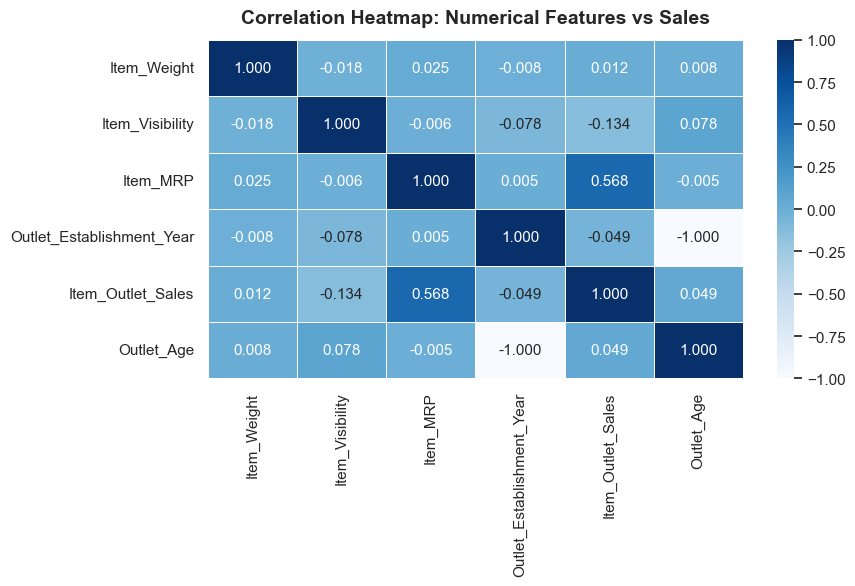

In [12]:
# Graph 1: Correlation Heatmap
plt.figure(figsize=(9, 6))
sns.heatmap(correlation_matrix, annot=True, cmap='Blues', fmt='.3f', linewidths=0.5, cbar=True)
plt.title('Correlation Heatmap: Numerical Features vs Sales', fontsize=14, fontweight='bold', pad=12)
plt.tight_layout()
plt.show()

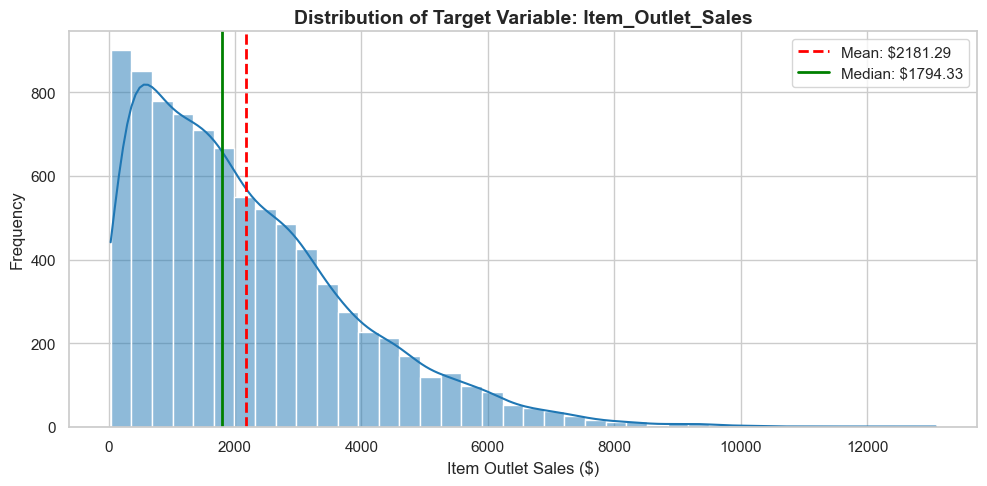

In [13]:
# Graph 2: Distribution of Target Variable (Item_Outlet_Sales)
fig, ax = plt.subplots(figsize=(10, 5))
sns.histplot(df['Item_Outlet_Sales'], kde=True, color='#1f77b4', bins=40, ax=ax)
ax.axvline(df['Item_Outlet_Sales'].mean(), color='red', linestyle='--', linewidth=2, label=f"Mean: ${df['Item_Outlet_Sales'].mean():.2f}")
ax.axvline(df['Item_Outlet_Sales'].median(), color='green', linestyle='-', linewidth=2, label=f"Median: ${df['Item_Outlet_Sales'].median():.2f}")
ax.set_title('Distribution of Target Variable: Item_Outlet_Sales', fontsize=14, fontweight='bold')
ax.set_xlabel('Item Outlet Sales ($)', fontsize=12)
ax.set_ylabel('Frequency', fontsize=12)
ax.legend(fontsize=11)
plt.tight_layout()
plt.show()

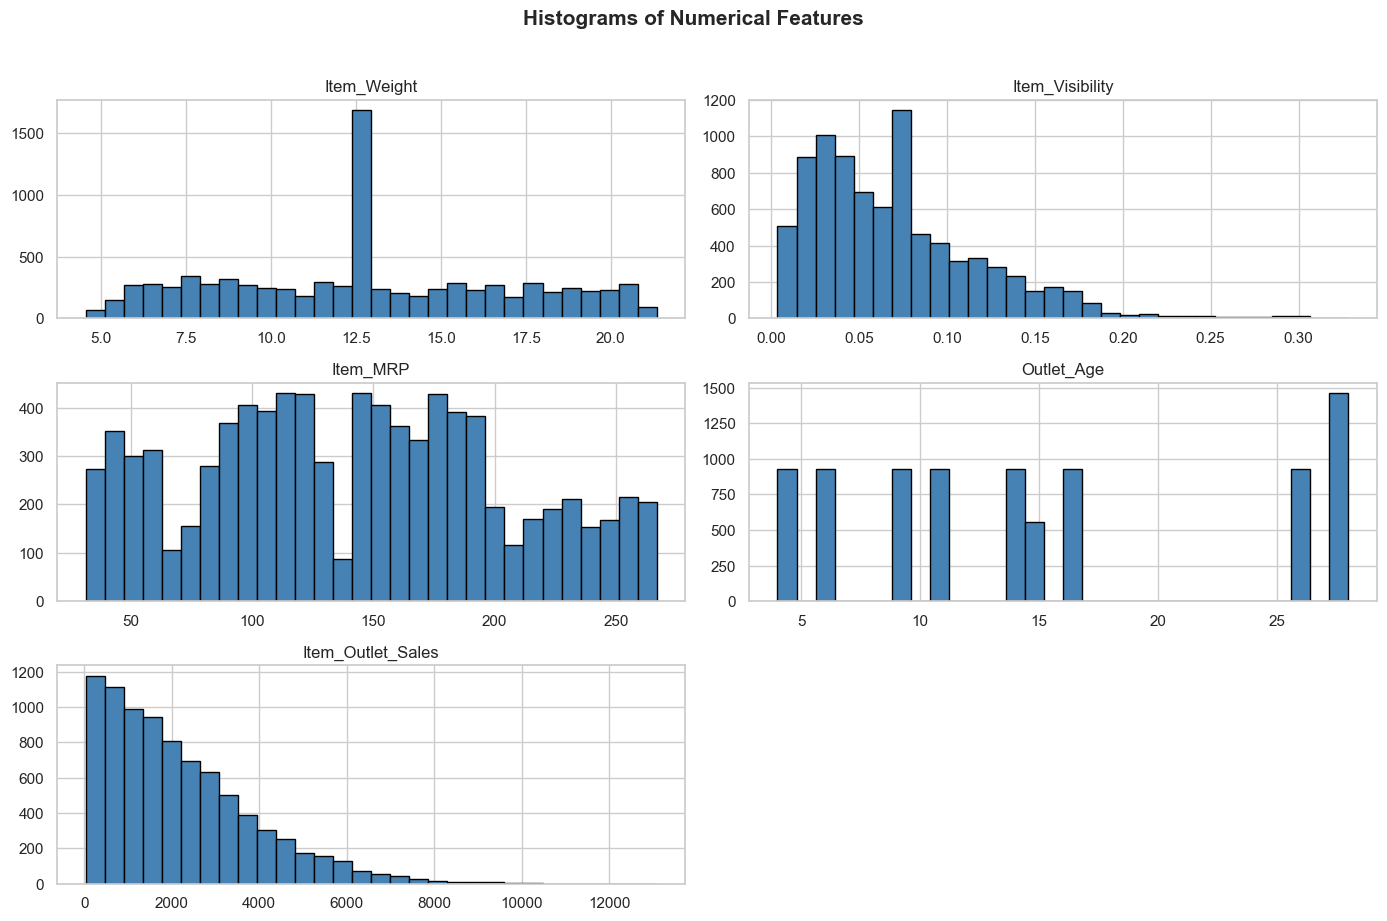

In [14]:
# Graph 3: Histograms for All Numerical Features
features_to_plot = ['Item_Weight', 'Item_Visibility', 'Item_MRP', 'Outlet_Age', 'Item_Outlet_Sales']
df[features_to_plot].hist(bins=30, figsize=(14, 9), color='steelblue', edgecolor='black', grid=True)
plt.suptitle('Histograms of Numerical Features', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

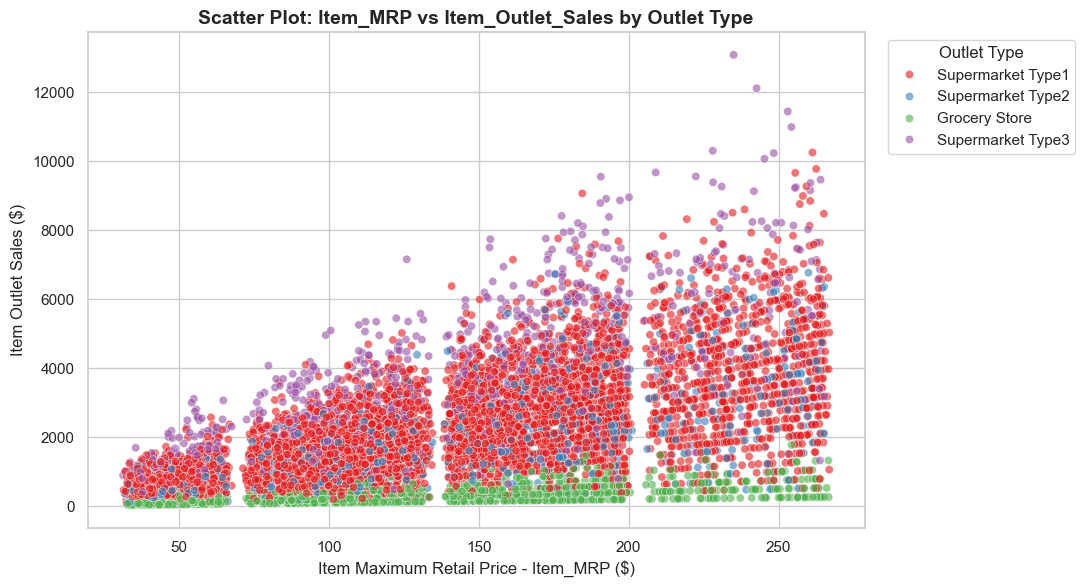

In [15]:
# Graph 4: Scatter Plot of Item_MRP vs Item_Outlet_Sales (Strongest Linear Predictor)
plt.figure(figsize=(11, 6))
sns.scatterplot(
    x='Item_MRP', 
    y='Item_Outlet_Sales', 
    hue='Outlet_Type', 
    data=df, 
    alpha=0.6, 
    palette='Set1'
)
plt.title('Scatter Plot: Item_MRP vs Item_Outlet_Sales by Outlet Type', fontsize=14, fontweight='bold')
plt.xlabel('Item Maximum Retail Price - Item_MRP ($)', fontsize=12)
plt.ylabel('Item Outlet Sales ($)', fontsize=12)
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', title='Outlet Type')
plt.tight_layout()
plt.show()

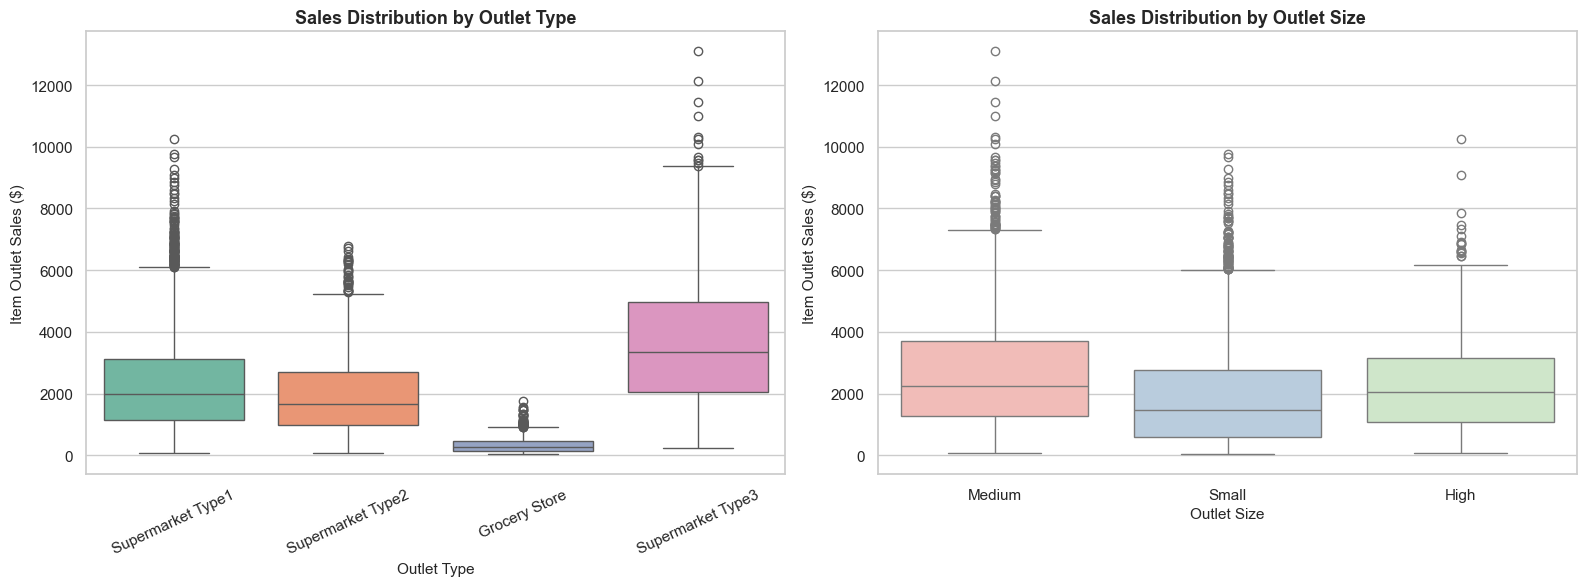

In [16]:
# Graph 5: Sales by Categorical Outlets (Outlet_Type & Outlet_Size)
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.boxplot(x='Outlet_Type', y='Item_Outlet_Sales', data=df, ax=axes[0], palette='Set2')
axes[0].set_title('Sales Distribution by Outlet Type', fontsize=13, fontweight='bold')
axes[0].tick_params(axis='x', rotation=25)
axes[0].set_xlabel('Outlet Type', fontsize=11)
axes[0].set_ylabel('Item Outlet Sales ($)', fontsize=11)

sns.boxplot(x='Outlet_Size', y='Item_Outlet_Sales', data=df, ax=axes[1], palette='Pastel1')
axes[1].set_title('Sales Distribution by Outlet Size', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Outlet Size', fontsize=11)
axes[1].set_ylabel('Item Outlet Sales ($)', fontsize=11)

plt.tight_layout()
plt.show()

Number of outliers identified (|Z-score| > 3): 90 (1.06%)


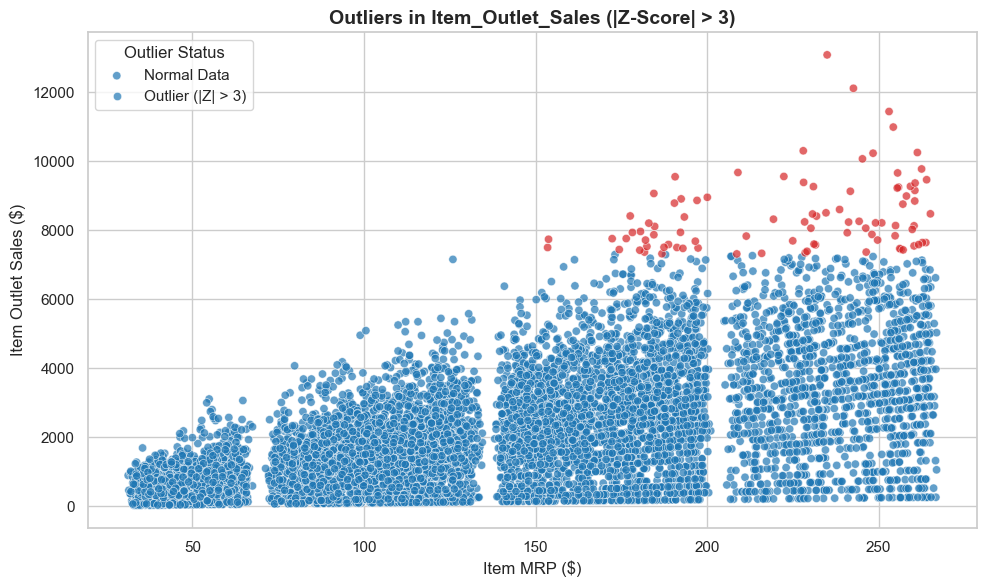

In [17]:
# Graph 6: Outlier Identification using Z-Score
# Calculating Z-scores for Item_Outlet_Sales
df['z_score_sales'] = stats.zscore(df['Item_Outlet_Sales'])
df['is_outlier'] = df['z_score_sales'].abs() > 3

num_outliers = df['is_outlier'].sum()
print(f"Number of outliers identified (|Z-score| > 3): {num_outliers} ({num_outliers / len(df) * 100:.2f}%)")

plt.figure(figsize=(10, 6))
sns.scatterplot(
    x='Item_MRP', 
    y='Item_Outlet_Sales', 
    hue='is_outlier', 
    data=df, 
    palette={False: '#1f77b4', True: '#d62728'}, 
    alpha=0.7
)
plt.title('Outliers in Item_Outlet_Sales (|Z-Score| > 3)', fontsize=14, fontweight='bold')
plt.xlabel('Item MRP ($)', fontsize=12)
plt.ylabel('Item Outlet Sales ($)', fontsize=12)
plt.legend(title='Outlier Status', labels=['Normal Data', 'Outlier (|Z| > 3)'])
plt.tight_layout()
plt.show()

---
## Step 7: Split the Dataset into Train and Testing Part
*Requirement 5 (Splitting): Split the dataset into train and testing part. Use 20% data of the dataset for testing.*

### Configuration:
- **Feature ($X$)**: For Simple Linear Regression, we select the feature with the highest correlation with sales: `Item_MRP` ($r = 0.568$).
- **Target ($y$)**: `Item_Outlet_Sales`.
- **Test Size**: `0.20` (20% testing, 80% training).
- **Random State**: `42` (ensures reproducible splits).

In [18]:
# Requirement 5: Train-test split (80% training, 20% testing)
X = df[['Item_MRP']]
y = df['Item_Outlet_Sales']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print("=== Train-Test Split Details ===")
print(f"Total Records:             {len(df)}")
print(f"Training Set Size (80%):    {X_train.shape[0]} samples")
print(f"Testing Set Size  (20%):    {X_test.shape[0]} samples")
print(f"Input Feature Matrix (X):  {X_train.shape}")
print(f"Target Output Vector (y):  {y_train.shape}")

=== Train-Test Split Details ===
Total Records:             8523
Training Set Size (80%):    6818 samples
Testing Set Size  (20%):    1705 samples
Input Feature Matrix (X):  (6818, 1)
Target Output Vector (y):  (6818,)


---
## Step 8: Train a Simple Linear Regression Model
*Requirement 6 (Training): Train a simple linear regression model on the dataset.*

Simple Linear Regression models the relationship between a single independent variable $X$ (`Item_MRP`) and the dependent continuous variable $y$ (`Item_Outlet_Sales`):

$$y = \beta_0 + \beta_1 X + \epsilon$$

Where:
- $\beta_0$ is the **Intercept** (expected sales when MRP is zero).
- $\beta_1$ is the **Slope / Coefficient** (change in sales for each $1 increase in MRP).
- $\epsilon$ is the error term.

In [19]:
# Requirement 6: Train Simple Linear Regression model
model = LinearRegression()
model.fit(X_train, y_train)

# Extract learned parameters
slope = model.coef_[0]
intercept = model.intercept_

print("=== Simple Linear Regression Model Parameters ===")
print(f"Slope (Coefficient, β1):  {slope:.4f}")
print(f"Intercept (β0):           {intercept:.4f}")
print(f"\nLearned Equation: Item_Outlet_Sales = {intercept:.2f} + {slope:.2f} * (Item_MRP)")

=== Simple Linear Regression Model Parameters ===
Slope (Coefficient, β1):  15.5455
Intercept (β0):           -3.6158

Learned Equation: Item_Outlet_Sales = -3.62 + 15.55 * (Item_MRP)


---
## Step 9: Evaluate the Model and Find Accuracy and Error
*Requirement 7: Evaluate the model and find the accuracy and Error (R2, MSE, RMSE).*

We evaluate the model using the standard regression metrics on the unseen testing set:
1. **$R^2$ Score (Coefficient of Determination / Accuracy)**:
   $$R^2 = 1 - \frac{\sum (y_i - \hat{y}_i)^2}{\sum (y_i - \bar{y})^2}$$
   Measures the proportion of variance in the target variable explained by the feature.
2. **Mean Squared Error (MSE)**:
   $$MSE = \frac{1}{n} \sum_{i=1}^n (y_i - \hat{y}_i)^2$$
   Penalizes larger errors heavily.
3. **Root Mean Squared Error (RMSE)**:
   $$RMSE = \sqrt{MSE}$$
   Expressed in the same unit as the target variable (Dollars).
4. **Mean Absolute Error (MAE)**:
   $$MAE = \frac{1}{n} \sum_{i=1}^n |y_i - \hat{y}_i|$$
   Average absolute error magnitude.

In [20]:
# Requirement 7: Predict on testing data and compute metrics
y_pred = model.predict(X_test)

# Calculate Evaluation Metrics
r2 = r2_score(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test, y_pred)

# Train vs Test accuracy (R2)
train_r2 = model.score(X_train, y_train)
test_r2 = model.score(X_test, y_test)

# Display Formatted Metrics
print("================ MODEL EVALUATION METRICS ================")
print(f"R-squared (R2 Score / Model Accuracy): {r2:.4f} ({r2*100:.2f}%)")
print(f"Mean Squared Error (MSE):             {mse:,.2f}")
print(f"Root Mean Squared Error (RMSE):        {rmse:,.2f}")
print(f"Mean Absolute Error (MAE):             {mae:,.2f}")
print("----------------------------------------------------------")
print(f"Training R2 Score:                     {train_r2:.4f} ({train_r2*100:.2f}%)")
print(f"Testing R2 Score:                      {test_r2:.4f} ({test_r2*100:.2f}%)")
print("==========================================================")

================ MODEL EVALUATION METRICS ================
R-squared (R2 Score / Model Accuracy): 0.3310 (33.10%)
Mean Squared Error (MSE):             1,818,215.32
Root Mean Squared Error (RMSE):        1,348.41
Mean Absolute Error (MAE):             991.47
----------------------------------------------------------
Training R2 Score:                     0.3196 (31.96%)
Testing R2 Score:                      0.3310 (33.10%)


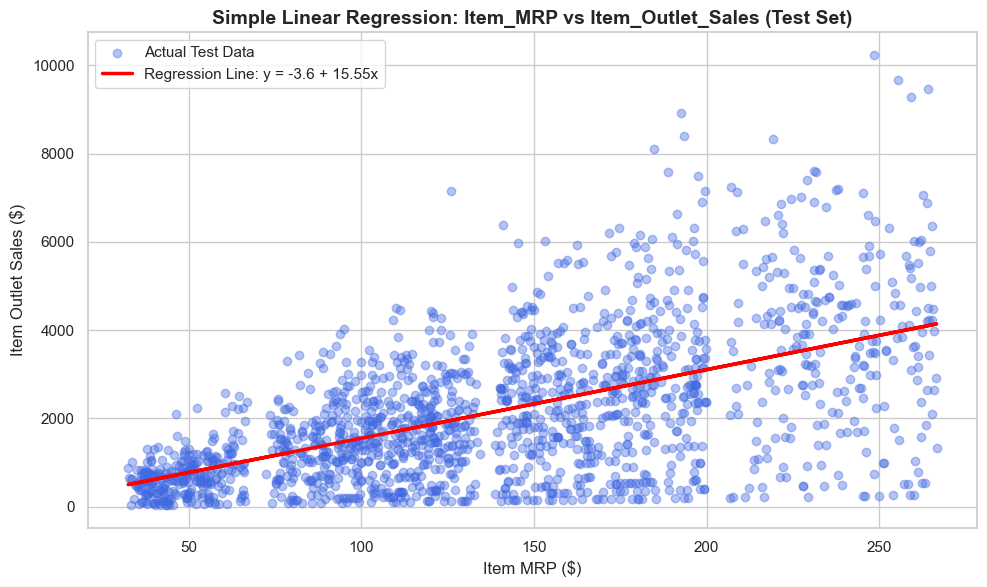

In [21]:
# Plot 1: Simple Linear Regression Line against Actual Test Points
plt.figure(figsize=(10, 6))
plt.scatter(X_test, y_test, color='royalblue', alpha=0.4, label='Actual Test Data')
plt.plot(X_test, y_pred, color='red', linewidth=2.5, label=f'Regression Line: y = {intercept:.1f} + {slope:.2f}x')
plt.title('Simple Linear Regression: Item_MRP vs Item_Outlet_Sales (Test Set)', fontsize=14, fontweight='bold')
plt.xlabel('Item MRP ($)', fontsize=12)
plt.ylabel('Item Outlet Sales ($)', fontsize=12)
plt.legend(fontsize=11)
plt.tight_layout()
plt.show()

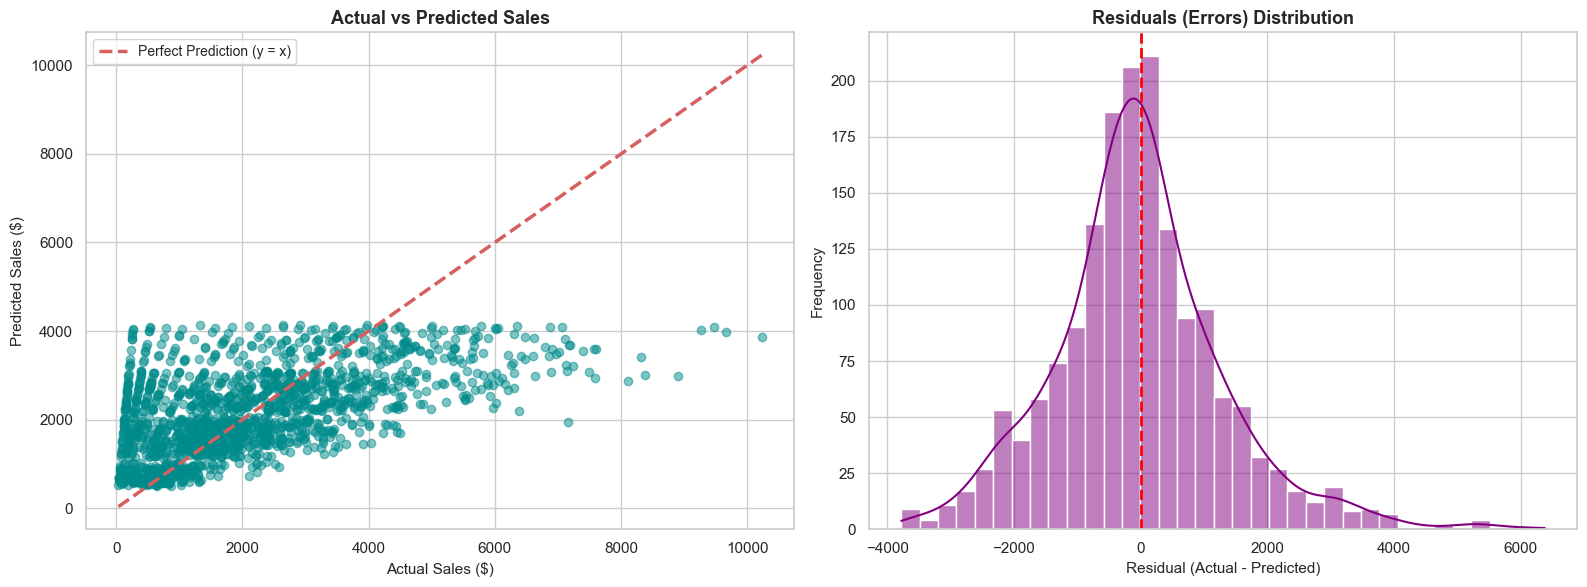

In [22]:
# Plot 2 & 3: Actual vs Predicted and Residuals Distribution
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Subplot 1: Actual vs Predicted
axes[0].scatter(y_test, y_pred, alpha=0.5, color='darkcyan')
axes[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2.5, label='Perfect Prediction (y = x)')
axes[0].set_title('Actual vs Predicted Sales', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Actual Sales ($)', fontsize=11)
axes[0].set_ylabel('Predicted Sales ($)', fontsize=11)
axes[0].legend(fontsize=10)

# Subplot 2: Residuals Distribution
residuals = y_test - y_pred
sns.histplot(residuals, kde=True, color='purple', bins=35, ax=axes[1])
axes[1].axvline(0, color='red', linestyle='--', lw=2)
axes[1].set_title('Residuals (Errors) Distribution', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Residual (Actual - Predicted)', fontsize=11)
axes[1].set_ylabel('Frequency', fontsize=11)

plt.tight_layout()
plt.show()

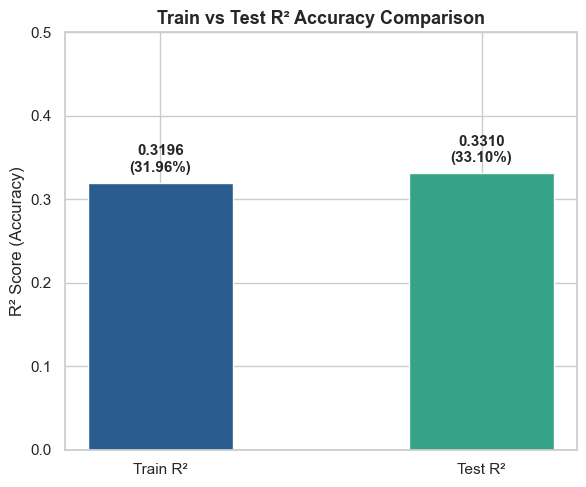

In [23]:
# Plot 4: Train vs Test R2 (Accuracy) Comparison Bar Chart
plt.figure(figsize=(6, 5))
bars = plt.bar(['Train R²', 'Test R²'], [train_r2, test_r2], color=['#2b5c8f', '#36a287'], width=0.45)
plt.ylim(0, 0.5)
plt.ylabel('R² Score (Accuracy)', fontsize=12)
plt.title('Train vs Test R² Accuracy Comparison', fontsize=13, fontweight='bold')

for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, height + 0.01, f"{height:.4f}\n({height*100:.2f}%)", ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()

---
## Step 10: Extension - Multiple Linear Regression Comparison
To explore whether incorporating additional features improves predictive performance, we encode categorical variables (`Item_Fat_Content`, `Item_Type`, `Outlet_Size`, `Outlet_Location_Type`, `Outlet_Type`) and train a **Multiple Linear Regression** model using all preprocessed attributes.

In [24]:
# Encode categorical columns using LabelEncoder
df_multi = df.copy()
le = LabelEncoder()
cat_cols = ['Item_Fat_Content', 'Item_Type', 'Outlet_Size', 'Outlet_Location_Type', 'Outlet_Type']
for col in cat_cols:
    df_multi[col] = le.fit_transform(df_multi[col])

# Feature set for Multiple Linear Regression
multi_features = ['Item_MRP', 'Item_Weight', 'Item_Visibility', 'Outlet_Age',
                  'Item_Fat_Content', 'Item_Type', 'Outlet_Size', 'Outlet_Location_Type', 'Outlet_Type']

X_multi = df_multi[multi_features]
y_multi = df_multi['Item_Outlet_Sales']

# Split data (80% train, 20% test)
X_train_m, X_test_m, y_train_m, y_test_m = train_test_split(
    X_multi, y_multi, test_size=0.20, random_state=42
)

# Train Multiple Linear Regression
multi_model = LinearRegression()
multi_model.fit(X_train_m, y_train_m)
y_pred_m = multi_model.predict(X_test_m)

# Compute Multiple Linear Regression Metrics
r2_m = r2_score(y_test_m, y_pred_m)
mse_m = mean_squared_error(y_test_m, y_pred_m)
rmse_m = np.sqrt(mse_m)

# Performance Comparison Table
model_comparison = pd.DataFrame({
    'Model': ['Simple Linear Regression (Item_MRP only)', 'Multiple Linear Regression (All Features)'],
    'R² Score (Accuracy)': [f"{r2:.4f} ({r2*100:.2f}%)", f"{r2_m:.4f} ({r2_m*100:.2f}%)"],
    'Mean Squared Error (MSE)': [f"{mse:,.2f}", f"{mse_m:,.2f}"],
    'Root Mean Squared Error (RMSE)': [f"${rmse:,.2f}", f"${rmse_m:,.2f}"]
})

print("=== Comparison: Simple Linear Regression vs. Multiple Linear Regression ===")
display(model_comparison)

=== Comparison: Simple Linear Regression vs. Multiple Linear Regression ===


,Model,R² Score (Accuracy),Mean Squared Error (MSE),Root Mean Squared Error (RMSE)
0,Simple Linear Regression (Item_MRP only),0.3310 (33.10%),"1,818,215.32","$1,348.41"
1,Multiple Linear Regression (All Features),0.5199 (51.99%),"1,305,004.69","$1,142.37"


---
## Summary and Key Conclusions

1. **Data Preprocessing & Cleaning**:
   - `Item_Fat_Content` inconsistencies (`LF`, `low fat`, `reg`) were standardized into `'Low Fat'` and `'Regular'`.
   - `Item_Visibility` zero values were handled by imputing the non-zero mean visibility.
   - Missing values in `Item_Weight` (1,463 rows) were imputed with the mean.
   - Missing values in `Outlet_Size` (2,410 rows) were imputed with the mode per `Outlet_Type`.
   - A derived feature, `Outlet_Age`, was engineered from `Outlet_Establishment_Year`.

2. **Correlation Analysis**:
   - `Item_MRP` demonstrated the strongest positive correlation with `Item_Outlet_Sales` ($r = 0.568$).
   - Other numerical variables had lower linear correlation with sales.

3. **Simple Linear Regression Results**:
   - **$R^2$ Score (Accuracy)**: **$0.3310$** ($33.10\%$) on unseen test data.
   - **MSE**: **$1,818,215.32$**
   - **RMSE**: **$\$1,348.41$**
   - The learned regression equation indicates that for every $1 increase in `Item_MRP`, sales increase by approximately $\$15.55$.

4. **Multiple Linear Regression Results**:
   - By incorporating store attributes (`Outlet_Type`, `Outlet_Size`, `Outlet_Age`) and product properties, $R^2$ increased from **$33.10\%$** to **$51.98\%$**, and RMSE decreased to **$\$1,142.40$**, showing significant predictive improvement.